# Modelo RL de gestão de banca
Protótipo didático de horizonte de uma vela. Execute as células em ordem. As onze seções seguem o roteiro acordado; ambiente, execução, calculadora e agente estão neste arquivo. O TFT fornece informação, e o agente controla a alocação e os níveis de saída.

**Convenções:** decisão após o fechamento de t, entrada no Open real de t+1, TP/SL relativos à entrada, encerramento obrigatório no Close real de t+1 se nenhum nível for atingido. Ambos atingidos: SL primeiro. Custos zero; banca inicial configurável de $100. Cada episódio reinicia essa banca. Não somamos saldos de episódios.

**Exposição, TP e SL são outputs contínuos**, sem catálogo de ações nem grade de distâncias. Aplicamos apenas exposição limitada pela banca e preços positivos no lado correto da entrada. Os 205 registros permitem testar a mecânica, mas não demonstram robustez. Monte Carlo fica para uma etapa futura: cenários precisam de trajetórias OHLC coerentes, não apenas features perturbadas.


## 1. Carregar e validar dados com alinhamento temporal

### Fontes de dados e referência temporal

- **Estado do RL:** features de risco e previsões disponíveis em *t*.
- **Dataset ambiente:** OHLC importado do histórico original, usado na execução em *t+1*.
- **Próximo período:** próxima vela do histórico, inclusive após fins de semana.

### Integridade e separação das informações

**O OHLC real futuro não entra na observação do agente.** A validação confere valores finitos, timestamps e correspondência do fechamento em *t*. Transições com OHLC inconsistente são excluídas e registradas, sem alterar preços ou substituir a vela seguinte.

### Detalhes e convenções

Importamos o estado de RL e, separadamente, o dataset original de OHLC. `Price` é o fechamento nesse arquivo; as datas originais usam mês/dia/ano. t+1 significa a **próxima linha de mercado**, inclusive após fins de semana, não o dia civil seguinte. O deslocamento ocorre no histórico original completo antes de selecionar os timestamps do estado.

O ambiente guarda o futuro em uma tabela separada de execução. As 29 features continuam sendo observações em t; nenhuma cotação real futura é acrescentada a elas. Conferimos se `cotation(t)` coincide com o fechamento original. Velas cujo High/Low não contenha Open e Close são inconsistentes: suas transições são excluídas e registradas, sem corrigir preços. O deslocamento é feito antes da exclusão, portanto nunca trocamos t+1 por uma vela posterior. Estas verificações não comprovam causalidade das features upstream: a produção de previsões e riscos deve ser auditada separadamente.


### 1.1 Bibliotecas e recursos locais

As bibliotecas são carregadas uma vez; toda a lógica operacional permanece no notebook.


In [1]:
from pathlib import Path
import copy, hashlib, json, random
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.distributions import Normal
import matplotlib.pyplot as plt
from IPython.display import display, HTML



### 1.2 Caminhos e reprodutibilidade

Localizamos o projeto e fixamos a **semente aleatória**.


In [2]:
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/processed/rl_state/rl_state.parquet').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Execute dentro do projeto Libellula.')
STATE_PATH = ROOT / 'data/processed/rl_state/rl_state.parquet'
RAW_PATH = ROOT / 'data/raw/EUR_USD.csv'
OUTPUT_DIR = ROOT / 'notebooks/modelo_RL_gestao_banca/resultados'
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(1)


### 1.3 Importação e validação do estado

Conferimos o contrato das **29 features** e a integridade do índice.


In [3]:
state = pd.read_parquet(STATE_PATH).sort_index()
state.index = pd.DatetimeIndex(pd.to_datetime(state.index), name='timestamp')
assert state.shape[1] == 29, 'Revisar contrato das 29 features.'
assert not state.index.has_duplicates and not state.columns.has_duplicates
assert np.isfinite(state.to_numpy(dtype=float)).all()


### 1.4 Importação do dataset ambiente

Interpretamos as datas originais e identificamos as velas com OHLC inconsistente.


In [4]:
raw = pd.read_csv(RAW_PATH)
raw['Date'] = pd.to_datetime(raw['Date'], format='%m/%d/%Y', errors='raise')
raw = raw.set_index('Date').sort_index()
assert not raw.index.has_duplicates
ohlc = raw[['Open', 'High', 'Low', 'Price']].rename(columns={'Price': 'Close'}).astype(float)
assert np.isfinite(ohlc.to_numpy()).all() and (ohlc > 0).all().all()
valid_ohlc = ((ohlc.High >= ohlc[['Open', 'Close', 'Low']].max(axis=1)) &
              (ohlc.Low <= ohlc[['Open', 'Close', 'High']].min(axis=1)))
assert state.index.isin(ohlc.index).all()
np.testing.assert_allclose(state['cotation(t)'], ohlc.loc[state.index, 'Close'], atol=1e-8)


### 1.5 Alinhamento do período real seguinte

O deslocamento ocorre **antes da exclusão** de transições inválidas.


In [5]:
future = ohlc.shift(-1)
future['execution_time'] = pd.Series(ohlc.index, index=ohlc.index).shift(-1)
future['valid_ohlc'] = valid_ohlc.shift(-1)
market = future.loc[state.index].copy()
assert not market.isna().any().any(), 'Existe t sem OHLC real seguinte.'
assert (market.execution_time.to_numpy() > state.index.to_numpy()).all()
excluded = market.loc[~market.valid_ohlc.astype(bool), ['execution_time']].copy()
if len(excluded):
    print('Transições excluídas por OHLC inconsistente (sem alterar preços):')
    display(excluded)
    state = state.loc[market.valid_ohlc.astype(bool)].copy()
    market = market.loc[state.index].copy()


Transições excluídas por OHLC inconsistente (sem alterar preços):


,execution_time
timestamp,
2025-01-06,2025-01-07
2025-04-18,2025-04-21


### 1.6 Conferência visual do alinhamento

Mostramos o tamanho utilizável e exemplos dos pares *t → t+1*.


In [6]:
print(f'Estado: {state.shape}; período: {state.index.min()} até {state.index.max()}')
display(pd.DataFrame({'t': state.index[:3], 't+1 real': market.execution_time.iloc[:3].to_numpy()}))


Estado: (203, 29); período: 2024-07-18 00:00:00 até 2025-04-30 00:00:00


,t,t+1 real
0,2024-07-18,2024-07-19
1,2024-07-19,2024-07-22
2,2024-07-22,2024-07-23


## 2. Definir observações, outputs sagrados e limites operacionais

### Outputs contínuos

- **Exposição:** fração contínua entre 0 e 1 do capital disponível.
- **TP e SL:** distâncias contínuas, convertidas em preços na abertura real de t+1.
- **Direção:** continua sendo o sinal de `pred_return` do TFT.

Não há catálogo de ações, grade de distâncias ou teto arbitrário de risco de 1%. A política aprende uma distribuição Normal em três variáveis latentes; transformações suaves asseguram a validade da operação. A precisão de ponto flutuante não constitui um catálogo discreto.

### Observação e contabilização

Mantemos **33 elementos**: 29 features padronizadas e quatro variáveis da banca. Quantidade = capital × exposição ÷ entrada. Vendas continuam sintéticas, sem modelar margem ou empréstimo. Custos continuam zero.


### 2.1 Parâmetros configuráveis

**Banca inicial e parâmetros de aprendizado.** Exposição, TP e SL são gerados continuamente pela política.


In [7]:
INITIAL_CAPITAL = 100.0
EPISODES = 80
LEARNING_RATE = 0.001
GAMMA = 0.99
ENTROPY_WEIGHT = 0.01
DRAWDOWN_PENALTY = 0.0  # opcional; baseline usa retorno relativo puro


### 2.2 Validade do espaço contínuo

Três variáveis reais, sem enumeração de escolhas. A conversão da etapa 5 garante exposição válida e preços positivos.


In [8]:
assert INITIAL_CAPITAL > 0 and EPISODES > 0
FEATURES = state.columns.tolist()
OBS_SIZE = len(FEATURES) + 4
ACTION_SIZE = 3


## 3. Inicializar banca e estado do ambiente

### Reinicialização de cada episódio

- **Capital e pico:** começam no valor inicial configurado.
- **Posições abertas:** nenhuma.
- **Histórico:** novo registro para cada episódio.

*Os saldos de episódios diferentes não são somados.*

### Detalhes e convenções

Cada episódio começa sem posições, com patrimônio e pico iguais ao capital inicial. O histórico é individual por episódio. `equity` representa o patrimônio realizado disponível na próxima decisão, porque não carregamos posições entre velas. Não existe transferência de lucros entre reinicializações de treino, validação ou teste.


In [9]:
class BankEnvironment:
    def __init__(self, features, execution, mean, scale):
        if len(features) == 0 or not features.index.equals(execution.index):
            raise ValueError('Bloco vazio ou desalinhado.')
        self.features, self.execution = features.copy(), execution.copy()
        self.mean, self.scale = mean, scale
        self.reset()

    def reset(self):
        self.i = 0
        self.equity = float(INITIAL_CAPITAL)
        self.peak = self.equity
        self.history = []
        self.done = False
        return self.observe()


## 4. Observar features de t + estado da banca

### Informação disponível no instante da decisão

- Features da linha corrente em *t*, padronizadas com estatísticas do treino.
- Patrimônio relativo ao capital inicial e drawdown atual.
- Exposição e posição aberta iguais a zero entre as operações.

**A observação não consulta a tabela OHLC futura.**

### Detalhes e convenções

A observação acessa somente a linha corrente das features e o patrimônio já realizado. A tabela OHLC futura é acessada apenas na execução. O pico permite medir drawdown sem consultar qualquer futuro. A transformação numérica tem média e desvio calculados exclusivamente no treino e fica congelada nos demais blocos.


In [10]:
def observe(self):
    if self.done:
        return np.zeros(OBS_SIZE, dtype=np.float32)
    x = (self.features.iloc[self.i].to_numpy(dtype=float) - self.mean) / self.scale
    bank = [self.equity / INITIAL_CAPITAL, 1 - self.equity / self.peak, 0.0, 0.0]
    observation = np.r_[x, bank].astype(np.float32)
    assert np.isfinite(observation).all()
    return observation
BankEnvironment.observe = observe


## 5. Gerar ação e convertê-la em uma operação válida

1. A rede fornece a **média de três variáveis contínuas**, dispersão aprendida e estimativa de valor.
2. No treino sorteamos ações; na avaliação usamos a média.
3. A logística transforma a exposição em fração entre 0 e 1.
4. Para níveis abaixo da entrada, a distância fica entre 0 e 1, garantindo preço positivo. Para níveis acima, `softplus` permite qualquer distância positiva, sem teto fixo.

**Não há grade de TP/SL nem teto arbitrário de risco.** Para compras, TP fica acima e SL abaixo; para vendas, o inverso. A decisão precede o conhecimento do Open futuro. Os vieses iniciais das distâncias são treináveis e não restringem o espaço de ações. A entropia usada no treino é a da distribuição latente.


### 5.1 Rede de política e valor

As duas cabeças compartilham uma representação das observações.


In [11]:
class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(OBS_SIZE, 64), nn.Tanh(), nn.Linear(64, 32), nn.Tanh())
        self.policy = nn.Linear(32, ACTION_SIZE)
        self.log_std = nn.Parameter(torch.full((ACTION_SIZE,), -0.5))
        self.value = nn.Linear(32, 1)
        with torch.no_grad():
            self.policy.bias.copy_(torch.tensor([0.0, -5.0, -5.0]))
    def forward(self, x):
        h = self.body(x)
        return self.policy(h), self.value(h).squeeze(-1)
    def distribution(self, location):
        return Normal(location, self.log_std.exp())



### 5.2 Conversão para os outputs sagrados

Transformações contínuas garantem **exposição válida e preços positivos no lado correto da entrada**, sem arredondamento ou catálogo de escolhas.


In [12]:
def sacred_outputs(action, predicted_return):
    action = np.asarray(action, dtype=float)
    if action.shape != (ACTION_SIZE,) or not np.isfinite(action).all():
        raise ValueError('A ação deve conter três valores reais finitos.')
    direction = int(np.sign(predicted_return))
    if direction == 0:
        return np.zeros(4, dtype=float)
    bounded = np.exp(-np.logaddexp(0.0, -action))
    positive = np.logaddexp(0.0, action)
    # Proteção contra preço zero por arredondamento de ponto flutuante.
    below = np.clip(bounded, np.finfo(float).eps, 1.0 - np.finfo(float).eps)
    above = np.maximum(positive, np.finfo(float).eps)
    exposure = bounded[0]
    tp = above[1] if direction > 0 else below[1]
    sl = below[2] if direction > 0 else above[2]
    return np.array([direction, exposure, tp, sl], dtype=float)


## 6. Executar usando OHLC real de t+1

### Regras de saída na vela real de t+1

1. **Somente TP atingido:** saída no TP.
2. **Somente SL atingido:** saída no SL.
3. **Ambos atingidos:** SL primeiro, pela convenção conservadora.
4. **Nenhum atingido:** saída no **Close real de t+1**.

*Toque exato no nível conta como execução. Compras e vendas têm níveis em sentidos opostos.*

### Detalhes e convenções

Entrada no Open de t+1. Comprado: TP acima e SL abaixo; vendido: TP abaixo e SL acima. Toque exato conta como execução. Verificamos SL antes de TP, incluindo a ambiguidade de ambos atingidos. Nenhum toque: saída no Close da mesma vela. Como os níveis são definidos em relação ao Open e não há posição herdada, não existe gap de posição aberta no protótipo.


In [13]:
def execute_trade(outputs, bar):
    direction, exposure, tp_distance, sl_distance = outputs
    entry = float(bar['Open'])
    if direction == 0 or exposure == 0:
        return {'entry': entry, 'exit': entry, 'tp': None, 'sl': None, 'reason': 'FORA'}
    tp = entry * (1 + direction * tp_distance)
    sl = entry * (1 - direction * sl_distance)
    tp_hit = bar['High'] >= tp if direction > 0 else bar['Low'] <= tp
    sl_hit = bar['Low'] <= sl if direction > 0 else bar['High'] >= sl
    if sl_hit:
        exit_price, reason = sl, 'SL_AMBOS' if tp_hit else 'SL'
    elif tp_hit:
        exit_price, reason = tp, 'TP'
    else:
        exit_price, reason = float(bar['Close']), 'CLOSE'
    return dict(entry=entry, exit=float(exit_price), tp=tp, sl=sl, reason=reason)


## 7. Calcular resultado líquido e atualizar banca

### Calculadora interna da banca

- **Quantidade:** capital anterior × exposição ÷ entrada.
- **Resultado:** direção × quantidade × (saída − entrada).
- **Novo capital:** capital anterior + resultado líquido.

**Custos são zero no protótipo.** O patrimônio é atualizado após liquidar a operação.

### Detalhes e convenções

Calculadora interna: quantidade = capital anterior × fração / entrada; P&L = direção × quantidade × (saída − entrada). Custos são exatamente zero neste estágio. Atualizamos a banca após a saída. O mesmo capital não é contado duas vezes: exposição é valor nocional, não um crédito ao patrimônio. Ruína encerra o episódio.


In [14]:
def settle_trade(capital, outputs, execution):
    direction, exposure, _, _ = outputs
    quantity = capital * exposure / execution['entry']
    gross = direction * quantity * (execution['exit'] - execution['entry'])
    costs = 0.0
    net = float(gross - costs)
    return dict(quantity=float(quantity), gross_pnl=float(gross), costs=costs,
                net_pnl=net, capital_after=float(capital + net))


## 8. Calcular recompensa e registrar a transição

### Recompensa e trilha de auditoria

- **Recompensa básica:** resultado líquido ÷ capital anterior.
- **Penalização opcional:** aumento do drawdown; coeficiente inicialmente zero.
- **Registro:** timestamps, ação, níveis, execução, quantidade, resultado e banca.

*Ficar fora produz recompensa zero; cada transição permanece disponível para inspeção.*

### Detalhes e convenções

Recompensa básica = lucro líquido / patrimônio anterior. Isso torna comparáveis bancas iniciais diferentes. Penalização opcional = coeficiente × aumento positivo do drawdown; começa em zero. Não operar recebe zero. Cada registro inclui timestamps de decisão e execução, outputs, entrada, TP/SL, saída, quantidade, resultado, capital, drawdown e recompensa. O treinamento usa observação, ação, recompensa e término; o registro serve para auditoria e monitoramento.


In [15]:
def register_transition(self, action, outputs, execution, settlement, before):
    previous_dd = 1 - before / self.peak
    self.equity = settlement['capital_after']
    self.peak = max(self.peak, self.equity)
    drawdown = 1 - self.equity / self.peak
    reward = settlement['net_pnl'] / before - DRAWDOWN_PENALTY * max(0, drawdown - previous_dd)
    row = dict(t=self.features.index[self.i], execution_time=self.execution.iloc[self.i]['execution_time'],
               action=np.asarray(action, dtype=float).tolist(), direction=int(outputs[0]), exposure=outputs[1],
               tp_distance=outputs[2], sl_distance=outputs[3], capital_before=before,
               drawdown=drawdown, reward=float(reward), **execution, **settlement)
    self.history.append(row)
    return float(reward), row
BankEnvironment.register_transition = register_transition


## 9. Avançar para o próximo período

### Encerrar a operação e avançar

1. Converter a ação e executar a operação.
2. Liquidar o resultado e registrar a transição.
3. Avançar **uma linha** ou encerrar o episódio.

**Nenhuma posição é carregada.** Após o término, uma nova ação exige reinicialização.

### Detalhes e convenções

`step` reúne as funções anteriores, liquida a operação e avança exatamente uma linha. Ao terminar o bloco ou perder a banca, devolve término e observação terminal zero. Nenhuma posição segue aberta. Chamadas depois do término são recusadas para impedir reutilização da última vela.


In [16]:
def step(self, action):
    if self.done:
        raise RuntimeError('Episódio encerrado; chame reset().')
    before = self.equity
    outputs = sacred_outputs(action, self.features.iloc[self.i]['pred_return'])
    execution = execute_trade(outputs, self.execution.iloc[self.i])
    settlement = settle_trade(before, outputs, execution)
    reward, info = self.register_transition(action, outputs, execution, settlement, before)
    self.i += 1
    self.done = self.i >= len(self.features) or self.equity <= 0
    return self.observe(), reward, self.done, info
BankEnvironment.step = step


## 10. Treinar e avaliar em blocos temporais separados

### Organização do treinamento

1. Separar **treino, validação e teste** em ordem temporal.
2. Ajustar a padronização exclusivamente no treino.
3. Treinar a política ator-crítico com episódios completos.
4. Selecionar pesos pelo capital final da validação.
5. Avaliar a política selecionada e destacar os capitais.

**Cada episódio começa com a banca inicial.** Repetir o histórico não cria novos cenários.

### Detalhes e convenções

Separação cronológica 70%/15%/15%. Removemos da borda dos blocos anteriores toda operação cujo t+1 alcance o primeiro timestamp do bloco seguinte. Assim, a vela executada no treino não atravessa a fronteira da validação. Normalizador ajustado só no treino.

Algoritmo ator-crítico episódico: acumulamos recompensas descontadas; a política recebe vantagem = retorno − valor estimado, e a cabeça de valor aprende esses retornos. A entropia incentiva exploração e o gradiente é limitado. Cada episódio percorre o mesmo histórico, portanto repetição não aumenta a diversidade dos dados. Selecionamos pesos pelo capital final da validação; teste é reservado para a avaliação final. A curva de treino usa ações sorteadas, enquanto validação e teste são determinísticos.

**Limite de interpretação:** o estado atual utiliza previsões do bloco de validação do TFT. A separação abaixo protege o treinamento do RL, mas não cria automaticamente um teste independente de todo o pipeline nem certifica ausência de vazamento nas features de risco.


### 10.1 Separação temporal e normalização

**As operações das bordas não atravessam o bloco seguinte.** As estatísticas são ajustadas apenas no treino.


In [17]:
n = len(state)
assert n >= 20
b1, b2 = int(n * .70), int(n * .85)
train_idx = state.index[:b1]
val_idx = state.index[b1:b2]
test_idx = state.index[b2:]
train_idx = train_idx[market.loc[train_idx, 'execution_time'].to_numpy() < val_idx[0]]
val_idx = val_idx[market.loc[val_idx, 'execution_time'].to_numpy() < test_idx[0]]
mean = state.loc[train_idx].mean().to_numpy()
scale = state.loc[train_idx].std(ddof=0).to_numpy()
scale = np.where(scale < 1e-12, 1.0, scale)


### 10.2 Ambientes e avaliação determinística

Construímos ambientes independentes e uma rotina de avaliação sem atualização de pesos.


In [18]:
def make_env(index):
    return BankEnvironment(state.loc[index], market.loc[index], mean, scale)

def rollout(model, index, fixed_action=None):
    env = make_env(index)
    obs = env.reset()
    with torch.no_grad():
        while not env.done:
            location, _ = model(torch.tensor(obs))
            action = location.numpy() if fixed_action is None else fixed_action
            obs, _, _, _ = env.step(action)
    return env



### 10.3 Inicialização do agente e acompanhamento

Criamos a rede, o otimizador e os registros de seleção na validação.


In [19]:
model = ActorCritic()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
training_rows = []
training_histories = []
validation_histories = []
best_score, best_weights, best_episode = -np.inf, None, None
last_train = None


### 10.4 Ciclo de aprendizado ator-crítico

O ciclo é mantido inteiro: coleta → retornos descontados → atualização dos pesos → validação. **Treino e avaliação usam bancas separadas.**


In [20]:
for episode in range(1, EPISODES + 1):
    env = make_env(train_idx)
    obs = env.reset()
    logs, values, entropies, rewards = [], [], [], []
    while not env.done:
        location, value = model(torch.tensor(obs))
        distribution = model.distribution(location)
        action = distribution.sample()
        obs, reward, _, _ = env.step(action.numpy())
        logs.append(distribution.log_prob(action).sum()); values.append(value)
        entropies.append(distribution.entropy().sum()); rewards.append(reward)
    returns, running = [], 0.0
    for reward in reversed(rewards):
        running = reward + GAMMA * running
        returns.append(running)
    targets = torch.tensor(list(reversed(returns)), dtype=torch.float32)
    estimates = torch.stack(values)
    advantage = targets - estimates.detach()
    policy_loss = -(torch.stack(logs) * advantage).mean()
    value_loss = (estimates - targets).square().mean()
    loss = policy_loss + .5 * value_loss - ENTROPY_WEIGHT * torch.stack(entropies).mean()
    assert torch.isfinite(loss)
    optimizer.zero_grad(); loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    validation = rollout(model, val_idx)
    validation_histories.append(pd.DataFrame(validation.history).assign(episode=episode))
    if validation.equity > best_score:
        best_score = validation.equity
        best_weights = copy.deepcopy(model.state_dict())
        best_episode = episode
    training_rows.append(dict(episode=episode, train_final=env.equity,
                             validation_final=validation.equity, loss=float(loss.detach()),
                             reward_sum=sum(rewards)))
    training_histories.append(pd.DataFrame(env.history).assign(episode=episode))
    last_train = env
    if episode == 1 or episode % 10 == 0:
        print(f'Episódio {episode}/{EPISODES}: treino ${env.equity:.4f}; validação ${validation.equity:.4f}')


Episódio 1/80: treino $99.8552; validação $102.3554
Episódio 10/80: treino $101.3703; validação $102.2391
Episódio 20/80: treino $100.5053; validação $102.2124
Episódio 30/80: treino $99.7478; validação $102.2851
Episódio 40/80: treino $98.7360; validação $102.3253
Episódio 50/80: treino $100.6555; validação $102.2559
Episódio 60/80: treino $99.7702; validação $102.2392
Episódio 70/80: treino $98.3309; validação $102.2308
Episódio 80/80: treino $102.5660; validação $102.2323


### 10.5 Avaliação dos pesos selecionados

Carregamos a política escolhida na validação e executamos os três blocos.


In [21]:
model.load_state_dict(best_weights)
train_evaluation = rollout(model, train_idx)
validation_evaluation = rollout(model, val_idx)
test_evaluation = rollout(model, test_idx)
progress = pd.DataFrame(training_rows)


### 10.6 Capital inicial e final em destaque

**O capital do último episódio de treino e o capital do teste aparecem separadamente.**


In [22]:
def capital_banner(label, capital):
    display(HTML(f'<div style="border:3px solid #167d9a;padding:20px;margin:12px 0">'
                 f'<h2>{label}</h2><p style="font-size:15px;font-weight:bold">'
                 f'CAPITAL INICIAL: ${INITIAL_CAPITAL:,.4f}<br>CAPITAL FINAL: ${capital:,.4f}</p></div>'))
capital_banner('TREINAMENTO — ÚLTIMO EPISÓDIO (BANCA REINICIADA)', last_train.equity)
capital_banner('TESTE TEMPORAL — POLÍTICA SELECIONADA NA VALIDAÇÃO', test_evaluation.equity)
print(f'Pesos selecionados: episódio {best_episode}. Blocos: {len(train_idx)}/{len(val_idx)}/{len(test_idx)}.')


Pesos selecionados: episódio 1. Blocos: 141/29/31.


## 11. Verificação de evolução do modelo

### Leitura dos resultados

- **Evolução:** capital por episódio e perda ator-crítico.
- **Gestão da banca:** patrimônio e drawdown no teste.
- **Operações:** quantidade, taxa de acerto e motivos de saída.
- **Comparação:** política RL, exposição fixa na direção do TFT e permanecer fora.

### Rastreabilidade

Pesos, normalizador, configurações, hashes e registros ficam em **`resultados`**.

*Perda menor não garante política melhor; modificar parâmetros após examinar o teste transforma esse bloco em validação.*

### Detalhes e convenções

Monitoramos capital por episódio, perda de treinamento, patrimônio por operação, drawdown máximo, retorno total, frequência de operações, taxa de acerto e motivos de saída. Perda menor não garante política melhor. A taxa de acerto considera somente posições efetivas; a curva inclui períodos fora do mercado.

Comparadores no mesmo teste: permanecer fora e exposição fixa na direção do TFT. Ambos partem da mesma banca e usam o mesmo executor. O teste deve continuar reservado: ajustar parâmetros após olhar seus resultados transforma esse bloco em validação.

Salvamos pesos, normalizador, contrato de ações, parâmetros, hashes dos insumos e registros por bloco na pasta `resultados`. Estes arquivos permitem inspecionar resultados e reconstruir a política, mas não retomam o otimizador de um treinamento interrompido. A exposição contínua pode se aproximar de zero; não existe uma ação categórica separada para ficar fora.


### 11.1 Métricas da banca e das operações

A taxa de acerto considera somente operações efetivas; o retorno usa a banca inicial.


In [23]:
def metrics(env):
    log = pd.DataFrame(env.history)
    trades = log[(log.direction != 0) & (log.exposure > 0)]
    return dict(initial=INITIAL_CAPITAL, final=env.equity,
                total_return=env.equity / INITIAL_CAPITAL - 1,
                max_drawdown=log.drawdown.max(), trades=len(trades),
                win_rate=float((trades.net_pnl > 0).mean()) if len(trades) else np.nan)


### 11.2 Comparadores no mesmo bloco de teste

Comparamos estratégias com **o mesmo executor e a mesma banca inicial**.


In [24]:
fixed_test = rollout(model, test_idx, fixed_action=np.array([np.log(.25 / .75), np.log(np.expm1(.005)), np.log(np.expm1(.005))]))
flat_test = rollout(model, test_idx, fixed_action=np.array([-1000.0, -5.0, -5.0]))
display(pd.DataFrame({'treino (política final)': metrics(train_evaluation),
                      'validação': metrics(validation_evaluation),
                      'teste RL': metrics(test_evaluation),
                      'teste exposição fixa': metrics(fixed_test),
                      'teste fora': metrics(flat_test)}).T)


,initial,final,total_return,max_drawdown,trades,win_rate
treino (política final),100.0,101.501261,0.015013,0.028476,141.0,0.489362
validação,100.0,102.355437,0.023554,0.005374,29.0,0.620690
teste RL,100.0,100.276142,0.002761,0.012330,31.0,0.451613
teste exposição fixa,100.0,99.683857,-0.003161,0.005450,31.0,0.419355
teste fora,100.0,100.000000,0.000000,0.000000,0.0,NaN


### 11.3 Gráficos de evolução

Os gráficos mostram capital por episódio, perda, patrimônio e drawdown.


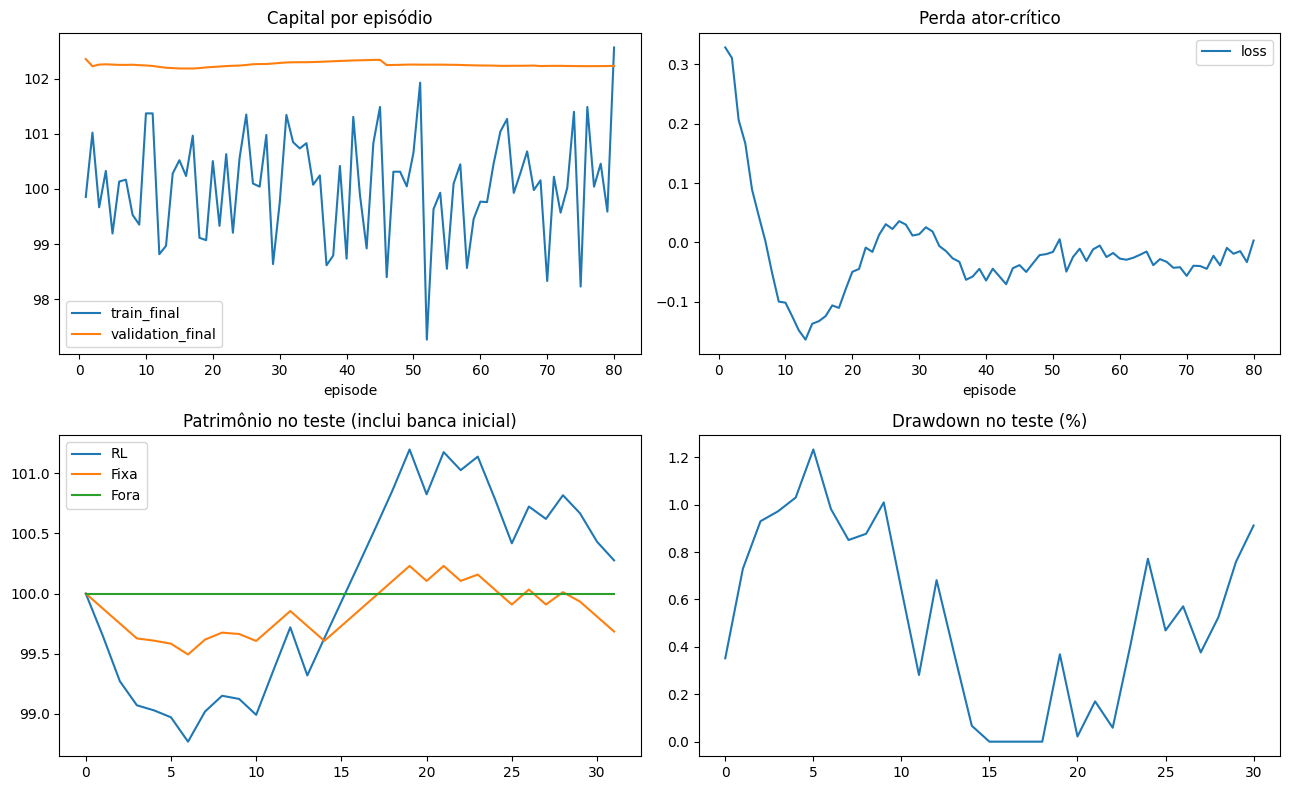

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
progress.plot(x='episode', y=['train_final', 'validation_final'], ax=axes[0, 0], title='Capital por episódio')
progress.plot(x='episode', y='loss', ax=axes[0, 1], title='Perda ator-crítico')
for label, env in [('RL', test_evaluation), ('Fixa', fixed_test), ('Fora', flat_test)]:
    values = [INITIAL_CAPITAL] + [r['capital_after'] for r in env.history]
    axes[1, 0].plot(values, label=label)
axes[1, 0].set_title('Patrimônio no teste (inclui banca inicial)'); axes[1, 0].legend()
test_log = pd.DataFrame(test_evaluation.history)
axes[1, 1].plot(test_log.drawdown.to_numpy() * 100)
axes[1, 1].set_title('Drawdown no teste (%)')
fig.tight_layout(); plt.show()


### 11.4 Cada operação e atualização de capital

**timestamp | Position_size | Take_profit | Stop_loss | Result | Capital_atualizado**

- **timestamp:** período real de execução, t+1.
- **Position_size:** valor monetário alocado, na unidade da banca; direção e quantidade constam do registro detalhado.
- **Take_profit / Stop_loss:** preços de saída, não distâncias.
- **Result:** lucro ou prejuízo líquido.
- **Capital_atualizado:** banca acumulada após a operação.

As tabelas incluem **todas as decisões**, sem truncamento. Cada episódio aparece em um painel expansível com sua própria banca. Decisões sem posição também são registradas, com alocação e resultado zero.


In [26]:
def operations_table(history):
    log = pd.DataFrame(history)
    return pd.DataFrame({
        'timestamp': log['execution_time'],
        'Position_size': log['capital_before'] * log['exposure'] * (log['direction'] != 0),
        'Take_profit': log['tp'],
        'Stop_loss': log['sl'],
        'Result': log['net_pnl'],
        'Capital_atualizado': log['capital_after'],
    })

def show_operations(label, history):
    table = operations_table(history)
    display(HTML(f'<details><summary><b>{label} — {len(table)} decisões</b></summary>'
                 + table.to_html(index=False, max_rows=None, max_cols=None) + '</details>'))

display(test_log.reason.value_counts().rename('ocorrências').to_frame())
for episode, history in enumerate(training_histories, start=1):
    show_operations(f'Treino — episódio {episode}', history)
for episode, history in enumerate(validation_histories, start=1):
    show_operations(f'Validação — episódio {episode}', history)
for label, env in [('Treino — política selecionada', train_evaluation),
                   ('Validação — política selecionada', validation_evaluation),
                   ('Teste — política selecionada', test_evaluation)]:
    show_operations(label, env.history)
show_operations('Comparador — exposição fixa', fixed_test.history)
show_operations('Comparador — fora', flat_test.history)


,ocorrências
reason,
CLOSE,15
TP,10
SL,6


timestamp,Position_size,Take_profit,Stop_loss,Result,Capital_atualizado
2024-07-19,42.337796,1.108005,1.080450,-0.093212,99.906788
2024-07-22,30.113518,1.095174,1.081828,0.022140,99.928928
2024-07-23,25.804164,1.098516,1.083445,-0.097133,99.831795
2024-07-24,53.126153,1.092413,1.075426,-0.073419,99.758376
2024-07-25,21.943302,1.091355,1.079649,0.008097,99.766473
2024-07-26,52.219706,1.098121,1.073604,0.048142,99.814615
2024-07-29,69.916044,1.090008,1.078328,-0.289601,99.525014
2024-07-30,56.761015,1.086267,1.077316,-0.031473,99.493542
2024-07-31,34.051290,1.093969,1.071170,0.028334,99.521876
2024-08-01,60.757634,1.089248,1.078436,-0.239295,99.282580


timestamp,Position_size,Take_profit,Stop_loss,Result,Capital_atualizado
2024-07-19,25.332905,1.106836,1.086707,-0.055774,99.944226
2024-07-22,46.141169,1.092070,1.085056,0.033924,99.978150
2024-07-23,53.635146,1.097521,1.085690,-0.172829,99.805322
2024-07-24,50.610416,1.093088,1.081844,-0.069943,99.735379
2024-07-25,75.120225,1.093985,1.080571,0.027720,99.763099
2024-07-26,77.104169,1.089394,1.079992,0.071083,99.834182
2024-07-29,71.740363,1.089893,1.077276,-0.297157,99.537025
2024-07-30,59.767357,1.102688,1.079030,-0.033140,99.503886
2024-07-31,62.755067,1.090922,1.070621,0.052219,99.556104
2024-08-01,43.563047,1.087146,1.080167,-0.101907,99.454197


timestamp,Position_size,Take_profit,Stop_loss,Result,Capital_atualizado
2024-07-19,30.407958,1.118487,1.075805,-0.066947,99.933053
2024-07-22,53.549041,1.102399,1.065615,0.039371,99.972424
2024-07-23,48.197927,1.092532,1.083660,-0.181428,99.790995
2024-07-24,58.997310,1.090554,1.079218,-0.081533,99.709462
2024-07-25,70.855135,1.090300,1.069820,0.026146,99.735608
2024-07-26,53.523172,1.092637,1.067699,0.049344,99.784952
2024-07-29,55.254392,1.090213,1.074465,-0.228870,99.556082
2024-07-30,33.913548,1.091724,1.076896,-0.018804,99.537277
2024-07-31,62.631304,1.096277,1.068922,0.052116,99.589393
2024-08-01,44.850089,1.093325,1.078640,-0.168193,99.421200


timestamp,Position_size,Take_profit,Stop_loss,Result,Capital_atualizado
2024-07-19,56.764838,1.097246,1.081211,-0.124975,99.875025
2024-07-22,54.816621,1.105755,1.075029,0.040303,99.915327
2024-07-23,39.478925,1.099424,1.074853,-0.148608,99.766720
2024-07-24,33.269182,1.088355,1.080726,-0.045977,99.720742
2024-07-25,46.660931,1.101897,1.078449,0.017218,99.737960
2024-07-26,44.036674,1.093196,1.077211,0.040598,99.778558
2024-07-29,28.390467,1.090978,1.065049,-0.117597,99.660962
2024-07-30,43.135400,1.091532,1.069481,-0.023918,99.637044
2024-07-31,38.082746,1.128646,1.073046,0.031689,99.668733
2024-08-01,59.843993,1.103985,1.074700,-0.198983,99.469750


...

timestamp,Position_size,Take_profit,Stop_loss,Result,Capital_atualizado
2024-07-19,48.732168,1.098471,1.083250,-0.107290,99.892710
2024-07-22,48.078443,1.096637,1.081644,0.035349,99.928058
2024-07-23,48.539794,1.097610,1.082522,-0.182715,99.745343
2024-07-24,48.816799,1.093729,1.078658,-0.067464,99.677879
2024-07-25,49.065727,1.092226,1.077205,0.018105,99.695985
2024-07-26,49.142438,1.092695,1.077514,0.045305,99.741290
2024-07-29,50.127767,1.094225,1.078762,-0.207635,99.533655
2024-07-30,48.720968,1.089740,1.074540,-0.027015,99.506640
2024-07-31,48.985108,1.089296,1.074063,0.040761,99.547401
2024-08-01,49.419324,1.090378,1.075035,-0.164320,99.383080


timestamp,Position_size,Take_profit,Stop_loss,Result,Capital_atualizado
2025-02-05,48.610100,1.031506,1.043537,-0.273447,99.726553
2025-02-06,47.252133,1.033666,1.045949,0.095395,99.821947
2025-02-07,46.791086,1.031789,1.044059,0.293424,100.115371
2025-02-10,46.651812,1.026011,1.038149,0.081338,100.196709
2025-02-11,46.290353,1.024292,1.036470,-0.259160,99.937549
2025-02-12,48.771088,1.029676,1.042033,-0.279271,99.658278
2025-02-13,45.788872,1.045371,1.032851,0.294075,99.952353
2025-02-14,47.677401,1.053591,1.040422,0.118453,100.070806
2025-02-17,47.556851,1.056056,1.042691,-0.031738,100.039068
2025-02-18,47.529857,1.041169,1.054599,0.176809,100.215877


timestamp,Position_size,Take_profit,Stop_loss,Result,Capital_atualizado
2025-03-19,58.944979,1.101872,1.087968,-0.351808,99.648192
2025-03-20,57.474573,1.097000,1.083132,-0.377873,99.270320
2025-03-21,57.275517,1.092686,1.078796,-0.200559,99.069760
2025-03-24,56.740637,1.088143,1.074474,-0.041999,99.027762
2025-03-25,56.944011,1.087400,1.073808,-0.057988,98.969774
2025-03-26,56.118748,1.086195,1.072768,-0.202820,98.766954
2025-03-27,56.278097,1.082340,1.068973,0.251218,99.018172
2025-03-28,56.571308,1.087098,1.073653,0.130928,99.149100
2025-03-31,57.192768,1.089312,1.075682,-0.026424,99.122675
2025-04-01,57.325501,1.088942,1.075280,-0.132477,98.990198


timestamp,Position_size,Take_profit,Stop_loss,Result,Capital_atualizado
2025-03-19,25.000000,1.099973,1.089041,-0.124688,99.875312
2025-03-20,24.968828,1.095751,1.084862,-0.124533,99.750779
2025-03-21,24.937695,1.090626,1.079788,-0.124377,99.626402
2025-03-24,24.906601,1.086204,1.075409,-0.018436,99.607966
2025-03-25,24.901992,1.085601,1.074812,-0.025358,99.582608
2025-03-26,24.895652,1.084495,1.073718,-0.089976,99.492632
2025-03-27,24.873158,1.080676,1.069937,0.124366,99.616998
2025-03-28,24.904249,1.085601,1.074812,0.057638,99.674636
2025-03-31,24.918659,1.087611,1.076803,-0.011513,99.663123
2025-04-01,24.915781,1.087209,1.076404,-0.057579,99.605544


timestamp,Position_size,Take_profit,Stop_loss,Result,Capital_atualizado
2025-03-19,0.0,None,None,0.0,100.0
2025-03-20,0.0,None,None,0.0,100.0
2025-03-21,0.0,None,None,0.0,100.0
2025-03-24,0.0,None,None,0.0,100.0
2025-03-25,0.0,None,None,0.0,100.0
2025-03-26,0.0,None,None,0.0,100.0
2025-03-27,0.0,None,None,0.0,100.0
2025-03-28,0.0,None,None,0.0,100.0
2025-03-31,0.0,None,None,0.0,100.0
2025-04-01,0.0,None,None,0.0,100.0


### 11.5 Salvamento dos artefatos

Salvamos os pesos, a padronização, os históricos e a figura de monitoramento.


In [27]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), OUTPUT_DIR / 'actor_critic.pth')
np.savez(OUTPUT_DIR / 'normalizer.npz', mean=mean, scale=scale)
progress.to_csv(OUTPUT_DIR / 'training_progress.csv', index=False)
for name, env in [('train', train_evaluation), ('validation', validation_evaluation),
                  ('test', test_evaluation), ('last_training_episode', last_train)]:
    pd.DataFrame(env.history).to_csv(OUTPUT_DIR / f'{name}_trades.csv', index=False)
    operations_table(env.history).to_csv(OUTPUT_DIR / f'{name}_operations.csv', index=False)
all_training = pd.concat(training_histories, ignore_index=True)
all_training.to_csv(OUTPUT_DIR / 'all_training_trades.csv', index=False)
all_validation = pd.concat(validation_histories, ignore_index=True)
all_validation.to_csv(OUTPUT_DIR / 'all_validation_trades.csv', index=False)
all_operations = pd.concat([operations_table(h).assign(episode=i)
                            for i, h in enumerate(training_histories, start=1)], ignore_index=True)
all_operations.to_csv(OUTPUT_DIR / 'all_training_operations.csv', index=False)
validation_operations = pd.concat([operations_table(h).assign(episode=i)
                                  for i, h in enumerate(validation_histories, start=1)], ignore_index=True)
validation_operations.to_csv(OUTPUT_DIR / 'all_validation_operations.csv', index=False)
fig.savefig(OUTPUT_DIR / 'monitoramento.png', dpi=150)


### 11.6 Manifesto de reprodutibilidade

O manifesto registra configurações, divisão temporal, **exclusões e hashes dos datasets**.


In [28]:
manifest = dict(seed=SEED, initial_capital=INITIAL_CAPITAL, episodes=EPISODES,
                best_episode=best_episode, features=FEATURES, action_space='continuous_normal_latent', action_size=ACTION_SIZE,
                excluded_transitions={str(t): str(row.execution_time) for t, row in excluded.iterrows()},
                exposure_domain=[0.0, 1.0], exit_prices='positive_directional', costs=0.0,
                learning_rate=LEARNING_RATE, gamma=GAMMA, entropy_weight=ENTROPY_WEIGHT,
                drawdown_penalty=DRAWDOWN_PENALTY,
                inputs={str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                        for p in [STATE_PATH, RAW_PATH]},
                splits={name: {'rows': len(idx), 'start': str(idx[0]), 'end': str(idx[-1])}
                        for name, idx in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]},
                train_last=metrics(last_train), test=metrics(test_evaluation))
(OUTPUT_DIR / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
print('Artefatos salvos em:', OUTPUT_DIR)


Artefatos salvos em: C:\projects\Libellula\notebooks\modelo_RL_gestao_banca\resultados
